<div dir="rtl" style="text-align:right">

# الفصل الرابع: Training Models (تدريب الموديلات)
### من كتاب *Hands-On Machine Learning with Scikit-Learn & TensorFlow*

لحد دلوقتي كنا بنتعامل مع الموديلات كأنها **Black Boxes**. الفصل ده بيفتح الصندوق ويوريك **إيه اللي بيحصل جوّه فعلًا** وإزاي الموديل بيتدرّب.

**ليه نفهم اللي جوّه؟**
- تقدر تختار الموديل والـ algorithm والـ hyperparameters الصح بسرعة.
- تقدر تعمل **debug** و**error analysis** بكفاءة أكتر.
- معظم الأفكار هنا أساسية لفهم **الـ Neural Networks** (الجزء التاني من الكتاب).

**خريطة الفصل:**

| القسم | الفكرة |
|---|---|
| Linear Regression | أبسط موديل، وطريقتين لتدريبه: **Normal Equation** (معادلة مباشرة) و**Gradient Descent** (تقريب تدريجي) |
| Gradient Descent | Batch / Stochastic / Mini-batch |
| Polynomial Regression | موديل خطي يفهم بيانات **مش خطية** |
| Learning Curves | نكتشف الـ **Overfitting** والـ **Underfitting** |
| Regularization | Ridge / Lasso / Elastic Net / Early Stopping |
| Logistic Regression | تصنيف لفئتين بالاحتمالات |
| Softmax Regression | تصنيف لعدة فئات مباشرة |

> **عن الرياضيات:** الفصل فيه معادلات كتير (جبر خطي وتفاضل بسيط). لو مش مرتاح معاها، اقرا الشرح بالكلمات والكود وهتفهم معظم الأفكار. أنا حاولت أشرح كل معادلة بالعربي.

> **تعديلات على كود الكتاب:** الكتاب قديم (2017) فاضطريت أعدّل شوية حاجات عشان الكود يشتغل على النسخ الحديثة (مثلًا `n_iter` بقت `max_iter`، و`np.int` بقت `int`). كل تعديل جنبه تعليق.

</div>

<div dir="rtl" style="text-align:right">

## 0) التجهيزات (Setup)

</div>

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")   # عشان نتجنب تحذيرات التقارب في بعض الأمثلة
np.random.seed(42)

mpl.rc("axes", labelsize=14)
mpl.rc("xtick", labelsize=12)
mpl.rc("ytick", labelsize=12)

<div dir="rtl" style="text-align:right">

## 1) Linear Regression (الانحدار الخطي)

في الفصل الأول شفنا موديل بسيط لـ life satisfaction:

$$\text{life\_satisfaction} = \theta_0 + \theta_1 \times \text{GDP\_per\_capita}$$

ده **دالة خطية** في الـ feature. وـ $\theta_0, \theta_1$ هما **parameters الموديل**.

### الصيغة العامة
الموديل الخطي بيعمل prediction عن طريق **مجموع موزون للـ features + ثابت** اسمه **bias term** (أو intercept):

$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \cdots + \theta_n x_n$$

- $\hat{y}$ = القيمة المتوقعة.
- $n$ = عدد الـ features.
- $x_i$ = قيمة الـ feature رقم i.
- $\theta_j$ = الـ parameter رقم j (بما فيهم الـ bias $\theta_0$ والأوزان $\theta_1...\theta_n$).

### الصيغة المتجهية (Vectorized)
$$\hat{y} = h_\theta(\mathbf{x}) = \boldsymbol{\theta}^T \cdot \mathbf{x}$$

- $\boldsymbol{\theta}$ = vector فيه كل الـ parameters.
- $\mathbf{x}$ = vector الـ features للعيّنة، ونعتبر $x_0 = 1$ دايمًا (عشان الـ bias يدخل في الضرب).
- $\boldsymbol{\theta}^T \cdot \mathbf{x}$ = **dot product** (ضرب داخلي).
- $h_\theta$ = **hypothesis function** (دالة الفرضية).

### إزاي ندرّبه؟
**تدريب الموديل = ضبط الـ parameters عشان الموديل يطابق الـ training set أحسن ما يمكن.**
فمحتاجين مقياس بيقول الموديل كويس ولا وحش. في الفصل التاني استخدمنا **RMSE**. وعمليًا أسهل نقلّل **MSE** بدل RMSE (النتيجة نفسها لأن اللي بيقلّل دالة بيقلّل جذرها كمان).

$$\text{MSE}(\mathbf{X}, h_\theta) = \frac{1}{m} \sum_{i=1}^{m} \left( \boldsymbol{\theta}^T \cdot \mathbf{x}^{(i)} - y^{(i)} \right)^2$$

يعني: **متوسط مربّع الفرق بين التوقع والقيمة الحقيقية.** وبنسمّيها **Cost Function**.

> أحيانًا الـ cost function اللي بنستخدمها في التدريب بتختلف عن مقياس الأداء اللي بنقيّم بيه الموديل في الآخر. السبب إما إنها أسهل في الحساب، أو مشتقاتها أحسن للـ optimization، أو لأننا عايزين نقيّد الموديل (regularization).

</div>

<div dir="rtl" style="text-align:right">

### 1.1) The Normal Equation (المعادلة الطبيعية)

فيه **حل مباشر (closed-form)**: معادلة رياضية بتديك قيمة $\theta$ اللي بتقلّل الـ cost function **على طول** من غير تكرار:

$$\hat{\boldsymbol{\theta}} = \left( \mathbf{X}^T \cdot \mathbf{X} \right)^{-1} \cdot \mathbf{X}^T \cdot \mathbf{y}$$

- $\hat{\boldsymbol{\theta}}$ = قيمة $\theta$ المثالية.
- $\mathbf{y}$ = vector القيم الحقيقية.

نولّد داتا شكلها خطي ($y = 4 + 3x + \text{noise}$) ونجرّب المعادلة عليها:

</div>

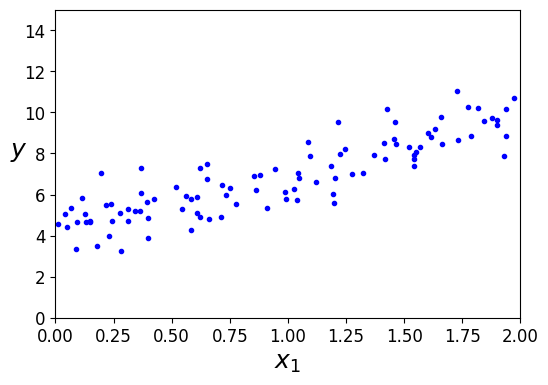

In [2]:
m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([0, 2, 0, 15])
plt.show()

In [3]:
X_b = np.c_[np.ones((m, 1)), X]    # نضيف x0 = 1 لكل عيّنة (عشان الـ bias)
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
theta_best

array([[4.21509616],
       [2.77011339]])

<div dir="rtl" style="text-align:right">

الدالة اللي ولّدت الداتا هي $y = 4 + 3x + \text{noise}$، يعني كنا نتمنى $\theta_0 = 4$ و$\theta_1 = 3$. طلعنا قريبين، **لكن الـ noise خلّى من المستحيل نسترجع الأرقام بالظبط.**

نستخدم $\hat{\theta}$ في عمل predictions:

</div>

In [4]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]   # نضيف x0 = 1
y_predict = X_new_b.dot(theta_best)
y_predict

array([[4.21509616],
       [9.75532293]])

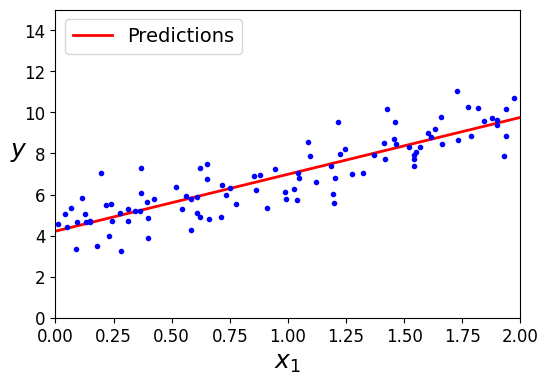

In [5]:
plt.figure(figsize=(6, 4))
plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.legend(loc="upper left", fontsize=14)
plt.axis([0, 2, 0, 15])
plt.show()

<div dir="rtl" style="text-align:right">

**نفس الحاجة بـ Scikit-Learn:** (ملحوظة: scikit-learn بتفصل الـ bias `intercept_` عن الأوزان `coef_`)

</div>

In [6]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
print("intercept:", lin_reg.intercept_, " coef:", lin_reg.coef_)
print(lin_reg.predict(X_new))

intercept: [4.21509616]  coef: [[2.77011339]]
[[4.21509616]
 [9.75532293]]


<div dir="rtl" style="text-align:right">

> **معلومة إضافية:** `LinearRegression` في scikit-learn مش بتحسب الـ inverse مباشرة، بتستخدم **SVD** (`scipy.linalg.lstsq`) وهو أكتر ثباتًا عدديًا. ونفس الحاجة ممكن تعملها بـ `np.linalg.pinv` (pseudoinverse) وبتشتغل حتى لو $X^T X$ مش قابلة للعكس.

</div>

In [7]:
# pseudoinverse: حل أكتر ثباتًا
theta_best_svd = np.linalg.pinv(X_b).dot(y)
theta_best_svd

array([[4.21509616],
       [2.77011339]])

<div dir="rtl" style="text-align:right">

### Computational Complexity (التعقيد الحسابي)

- المعادلة بتحسب **inverse** لمصفوفة $X^T X$ حجمها $n \times n$ ($n$ = عدد الـ features). تعقيد ده حوالي $O(n^{2.4})$ لـ $O(n^3)$.
  يعني لو **ضاعفت عدد الـ features** هيزيد الوقت من **5 لـ 8 أضعاف** تقريبًا.
- **بتبقى بطيئة جدًا** لما $n$ يكبر (مثلًا 100,000 feature).
- **على الجانب الإيجابي:** خطية بالنسبة لعدد العيّنات $m$ ($O(m)$)، فبتتعامل كويس مع training sets كبيرة طالما بتدخل في الذاكرة.
- بعد التدريب، الـ **predictions سريعة جدًا** (خطية بالنسبة لعدد العيّنات وعدد الـ features).

دلوقتي هنشوف طرق تدريب تانية أنسب لما يكون عندنا **features كتير** أو **عيّنات كتير ما تدخلش في الذاكرة**.

</div>

<div dir="rtl" style="text-align:right">

## 2) Gradient Descent (النزول التدريجي)

**Gradient Descent** خوارزمية optimization عامة جدًا بتلاقي الحلول المثالية لمشاكل كتير. الفكرة: **نعدّل الـ parameters بشكل تدريجي (iteratively) عشان نقلّل الـ cost function.**

### 🏔️ التشبيه
تخيّل إنك تايه في **جبل وسط ضباب كثيف**، وما تقدرش تحس غير بميلان الأرض تحت رجليك. أحسن استراتيجية توصل لقاع الوادي بسرعة: **امشي في اتجاه أشد انحدار لتحت.** ده بالظبط اللي بيعمله Gradient Descent:
1. بيقيس **الـ gradient** (ميل الـ cost function) بالنسبة لـ $\theta$.
2. بيمشي في اتجاه **الـ gradient النازل**.
3. لما الـ gradient يبقى صفر، وصلت لـ minimum!

**الخطوات:**
1. نبدأ بـ $\theta$ بقيم **عشوائية** (**random initialization**).
2. نحسّنها تدريجيًا، خطوة صغيرة كل مرة، لحد ما الـ algorithm **يتقارب (converges)** لـ minimum.

### Learning Rate (معدّل التعلم $\eta$)
بيتحكم في **حجم الخطوة**:
- **صغير قوي** ← محتاج iterations كتير جدًا (بطيء).
- **كبير قوي** ← ممكن تقفز فوق الوادي وتوصل لمكان أعلى من اللي كنت فيه. الـ algorithm **بيتباعد (diverge)**.

### تحديات Gradient Descent
مش كل الـ cost functions شكلها وعاء منتظم. ممكن يبقى فيها:
- **Local Minimum:** قاع محلي مش أحسن حاجة (لو بدأت من مكان وحش).
- **Plateau (هضبة):** منطقة مسطحة بياخد وقت طويل جدًا لعبورها، ولو وقفت بدري مش هتوصل للـ global minimum.

### ✅ خبر حلو لـ Linear Regression
دالة الـ MSE في Linear Regression **convex** (محدّبة): لو اخترت أي نقطتين على المنحنى، الخط اللي بيوصل بينهم **ما بيقطعش المنحنى أبدًا**. ده معناه:
- مفيش local minima، **فيه global minimum واحد بس**.
- ميلها ما بيتغيرش فجأة (continuous).

**النتيجة:** Gradient Descent **مضمون** يقرّب من الـ global minimum قد ما تحب (لو استنيت كفاية ولو الـ learning rate مش كبير).

### ⚠️ Feature Scaling مهم جدًا
شكل الـ cost function وعاء، لكن لو الـ features **مقاييسها مختلفة جدًا** بيبقى الوعاء **مستطيل ومتطاول**، فالـ algorithm بيمشي في اتجاه شبه عمودي على الـ minimum الأول وبعدين يعمل "مسيرة طويلة" في وادي شبه مسطح. بيوصل في الآخر لكن **بعد وقت طويل**.

> **اتأكد دايمًا إن كل الـ features ليها مقياس متقارب** (باستخدام `StandardScaler` مثلًا) قبل Gradient Descent.

وده بيوضّح إن **التدريب = بحث في فضاء الـ parameters**. كل ما زاد عدد الـ parameters زادت الأبعاد وصعب البحث (إبرة في كومة قش بـ 300 بُعد أصعب من 3 أبعاد). بس لحسن الحظ، الـ cost function هنا convex، فالإبرة دايمًا في **قاع الوعاء**.

</div>

<div dir="rtl" style="text-align:right">

### 2.1) Batch Gradient Descent

عشان نطبّق Gradient Descent لازم نحسب **الـ gradient** للـ cost function بالنسبة لكل parameter $\theta_j$. يعني: **"لو غيّرت $\theta_j$ شوية صغيرة، الـ cost هتتغير قد إيه؟"** ده اسمه **partial derivative** (مشتقة جزئية). تخيّل إنك بتسأل: "إيه ميل الجبل تحت رجلي لو بصيت ناحية الشرق؟" وبعدين الشمال، وهكذا لكل الأبعاد.

$$\frac{\partial}{\partial \theta_j} \text{MSE}(\boldsymbol{\theta}) = \frac{2}{m} \sum_{i=1}^{m} \left( \boldsymbol{\theta}^T \cdot \mathbf{x}^{(i)} - y^{(i)} \right) x_j^{(i)}$$

بدل ما نحسبهم واحد واحد، نحسبهم **كلهم مرة واحدة** في **gradient vector**:

$$\nabla_\theta \text{MSE}(\boldsymbol{\theta}) = \frac{2}{m} \mathbf{X}^T \cdot (\mathbf{X} \cdot \boldsymbol{\theta} - \mathbf{y})$$

> لاحظ إن المعادلة دي بتستخدم **الـ training set كله** في كل خطوة! عشان كده اسمها **Batch** Gradient Descent (بتستخدم الـ batch كله). نتيجة ذلك: **بطيئة جدًا** مع الـ training sets الكبيرة. لكنها **بتتحمّل عدد features كبير جدًا** (أسرع بكتير من Normal Equation لو عندك مئات الآلاف من الـ features).

الـ gradient vector **بيشاور لفوق** (الاتجاه الأعلى)، فنمشي في الاتجاه **المعاكس** (نطرحه من $\theta$). والـ **learning rate $\eta$** بيحدد حجم الخطوة:

$$\boldsymbol{\theta}^{(\text{next step})} = \boldsymbol{\theta} - \eta \nabla_\theta \text{MSE}(\boldsymbol{\theta})$$

</div>

In [8]:
eta = 0.1              # learning rate
n_iterations = 1000
m = 100

theta = np.random.randn(2, 1)     # random initialization

for iteration in range(n_iterations):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients

theta

array([[4.21509616],
       [2.77011339]])

<div dir="rtl" style="text-align:right">

ده **بالظبط** اللي طلعته الـ Normal Equation! Gradient Descent اشتغل تمام.

### تأثير الـ Learning Rate
هنشوف أول 10 خطوات بـ 3 قيم مختلفة لـ $\eta$ (الخط المتقطع الأحمر = نقطة البداية):

</div>

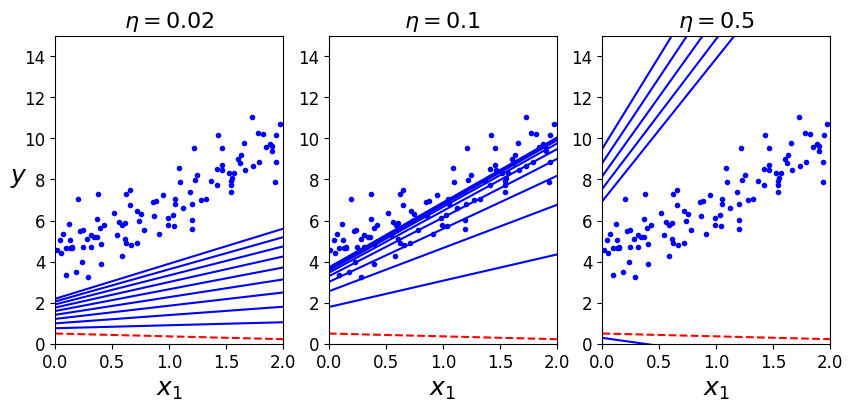

In [9]:
theta_path_bgd = []

def plot_gradient_descent(theta, eta, theta_path=None):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_iterations = 1000
    for iteration in range(n_iterations):
        if iteration < 10:
            y_predict = X_new_b.dot(theta)
            style = "b-" if iteration > 0 else "r--"
            plt.plot(X_new, y_predict, style)
        gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
        theta = theta - eta * gradients
        if theta_path is not None:
            theta_path.append(theta)
    plt.xlabel("$x_1$", fontsize=18)
    plt.axis([0, 2, 0, 15])
    plt.title(r"$\eta = {}$".format(eta), fontsize=16)

np.random.seed(42)
theta = np.random.randn(2, 1)

plt.figure(figsize=(10, 4))
plt.subplot(131); plot_gradient_descent(theta, eta=0.02)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.subplot(132); plot_gradient_descent(theta, eta=0.1, theta_path=theta_path_bgd)
plt.subplot(133); plot_gradient_descent(theta, eta=0.5)
plt.show()

<div dir="rtl" style="text-align:right">

- **الشمال ($\eta=0.02$):** الـ learning rate **صغير جدًا**. هيوصل للحل في الآخر لكن **بعد وقت طويل**.
- **النص ($\eta=0.1$):** ممتاز! وصل للحل في كام iteration بس.
- **اليمين ($\eta=0.5$):** **كبير جدًا**. الـ algorithm **بيتباعد**: بيقفز في كل مكان وبيبعد أكتر عن الحل مع كل خطوة.

**إزاي أختار learning rate؟** باستخدام **grid search** (من الفصل التاني)، مع تحديد عدد iterations عشان الموديلات اللي بتتأخر في التقارب تتستبعد.

**وعدد الـ iterations؟** لو قليل: هتبقى لسه بعيد عن الحل. لو كتير: هتضيّع وقت والـ parameters ما بتتغيرش. **الحل البسيط:** حدد عدد كبير جدًا، وبعدين **وقّف الـ algorithm لما الـ gradient vector يبقى صغير جدًا**، يعني لما **norm** بتاعه يبقى أصغر من رقم تافه $\epsilon$ (بنسميه **tolerance**)، لأن ده بيحصل لما نوصل (تقريبًا) للـ minimum.

</div>

In [10]:
# إيقاف الـ Gradient Descent عند tolerance
epsilon = 1e-6
eta = 0.1
np.random.seed(42)
theta = np.random.randn(2, 1)

for iteration in range(100000):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    if np.linalg.norm(gradients) < epsilon:
        print("وقفنا بعد", iteration, "iteration")
        break
    theta = theta - eta * gradients

print(theta.ravel())

وقفنا بعد 365 iteration
[4.21509399 2.7701153 ]


<div dir="rtl" style="text-align:right">

> **Convergence Rate (معدّل التقارب):** لما الـ cost function convex وميلها ما بيتغيرش فجأة، Batch GD بـ learning rate ثابت بيتقارب بمعدّل $O(1/\text{iterations})$. يعني لو قسّمت الـ tolerance $\epsilon$ على 10 (عشان دقة أكتر)، الـ algorithm هيحتاج **حوالي 10 أضعاف** الـ iterations.

### تجربة عملية: أثر الـ Feature Scaling على Gradient Descent
هنقارن عدد الـ iterations اللازمة لنفس المشكلة: مرة والـ features **مقاييسها مختلفة جدًا**، ومرة بعد الـ **scaling**.

</div>

In [11]:
from sklearn.preprocessing import StandardScaler

rng = np.random.RandomState(42)
m2 = 200
x1 = rng.rand(m2, 1)            # feature صغيرة (0 → 1)
x2 = rng.rand(m2, 1) * 100      # feature كبيرة (0 → 100)
y2 = 4 + 3 * x1 + 0.05 * x2 + rng.randn(m2, 1) * 0.1

def gd_iterations(Xf, yf, tol=1e-4, max_iter=200000):
    # Batch GD بأكبر learning rate "آمن" محسوب من المصفوفة نفسها
    Xb = np.c_[np.ones((len(Xf), 1)), Xf]
    mm = len(Xb)
    eta = 1.0 / np.linalg.eigvalsh(2/mm * Xb.T.dot(Xb)).max()
    theta = np.zeros((Xb.shape[1], 1))
    for it in range(max_iter):
        g = 2/mm * Xb.T.dot(Xb.dot(theta) - yf)
        if np.linalg.norm(g) < tol:
            return it, True
        theta = theta - eta * g
    return max_iter, False

raw = np.c_[x1, x2]
scaled = StandardScaler().fit_transform(raw)

print("بدون scaling:", gd_iterations(raw, y2))      # (عدد الـ iterations, هل اتقارب؟)
print("مع scaling  :", gd_iterations(scaled, y2))

بدون scaling: (200000, False)
مع scaling  : (4, True)


<div dir="rtl" style="text-align:right">

بدون scaling الـ Gradient Descent إما بياخد **آلاف أضعاف** الـ iterations أو **ما بيوصلش** للـ tolerance أصلًا، ومع الـ scaling بيخلّص في كام iteration بس. **المعادلة الطبيعية (Normal Equation) ما بتتأثرش بالـ scaling**، لكن Gradient Descent بيتأثر.

</div>

<div dir="rtl" style="text-align:right">

### 2.2) Stochastic Gradient Descent (SGD)

**المشكلة الأساسية في Batch GD:** بيستخدم الـ training set كله في كل خطوة، فبيبقى بطيء جدًا على الداتا الكبيرة.

**على النقيض:** Stochastic GD بياخد **عيّنة عشوائية واحدة** في كل خطوة ويحسب الـ gradients عليها وبس.

**المميزات:**
- **أسرع بكتير** (داتا قليلة في كل iteration).
- ممكن يتدرّب على **داتا ضخمة** لأن عيّنة واحدة بس لازم تبقى في الذاكرة (**out-of-core algorithm**).

**العيوب:**
- طبيعته **عشوائية** فهو **أقل انتظامًا** بكتير: الـ cost بتتنطط لفوق وتحت وبتنزل **في المتوسط بس**.
- عند الوصول للـ minimum **بيفضل يتنطط حواليه** ومش بيستقر. فالقيم النهائية **كويسة لكن مش مثالية**.

**الميزة الغريبة:** لو الـ cost function غير منتظمة (فيها local minima)، العشوائية **بتساعد الـ algorithm يقفز خارج الـ local minima**. فـ SGD عنده فرصة أحسن يلاقي الـ global minimum من Batch GD.

### Simulated Annealing (التبريد المحاكى)
مشكلة: العشوائية كويسة للهروب من الـ local optima، لكن وحشة لأنها مش بتسيب الـ algorithm يستقر. **الحل: نقلّل الـ learning rate تدريجيًا.**
- الخطوات تبدأ **كبيرة** (تقدّم سريع وهروب من local minima).
- وبعدين **تصغر وتصغر** (عشان يستقر عند الـ global minimum).

اسمه كده لأنه بيشبه **annealing** في المعادن (تبريد المعدن المنصهر ببطء). والدالة اللي بتحدد الـ learning rate في كل iteration اسمها **learning schedule**.
- لو قلّلت الـ rate **بسرعة قوي** ← ممكن تتعلق في local minimum أو "تتجمد" في نص الطريق.
- لو قلّلته **ببطء قوي** ← هتفضل تنط حوالين الـ minimum وقت طويل.

**Epoch:** بالاتفاق، بنكرر على دفعات من $m$ iteration، وكل دفعة اسمها **epoch**.

</div>

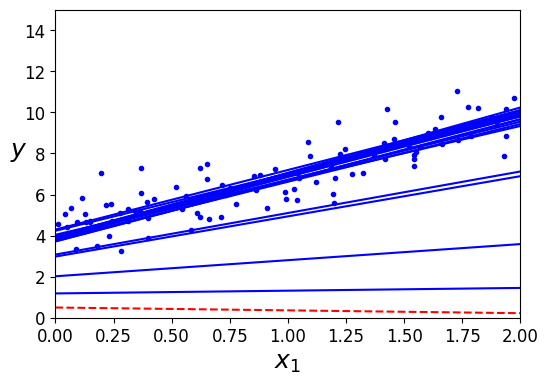

array([[4.21076011],
       [2.74856079]])

In [12]:
n_epochs = 50
t0, t1 = 5, 50        # hyperparameters بتاعة الـ learning schedule

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)    # random initialization
theta_path_sgd = []

plt.figure(figsize=(6, 4))
for epoch in range(n_epochs):
    for i in range(m):
        if epoch == 0 and i < 20:                    # أول 20 خطوة بس للرسم
            y_predict = X_new_b.dot(theta)
            style = "b-" if i > 0 else "r--"
            plt.plot(X_new, y_predict, style)
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2 * xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)

plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([0, 2, 0, 15])
plt.show()

theta

<div dir="rtl" style="text-align:right">

**لاحظ:** Batch GD لفّ 1000 مرة على الـ training set كله، أما SGD هنا لف **50 مرة بس** (50 epoch) ووصل لحل كويس جدًا. والرسمة بتوضّح كمية العشوائية في أول 20 خطوة.

> ⚠️ لأن العيّنات بتتختار **عشوائيًا**، ممكن عيّنة تتختار أكتر من مرة في الـ epoch وعيّنات تانية ما تتختارش خالص. لو عايز تضمن إن كل عيّنة تتستخدم في كل epoch: اخلط الـ training set (shuffle)، وامشي عليه عيّنة عيّنة، وبعدين اخلطه تاني. لكن ده **غالبًا بيتقارب أبطأ**.

#### SGD في Scikit-Learn: `SGDRegressor`
بتستخدم squared error كـ cost function افتراضيًا. هنا: 50 epoch، `eta0=0.1`، الـ learning schedule الافتراضي (مختلف عن اللي فوق)، وبدون regularization (`penalty=None`).

</div>

In [13]:
from sklearn.linear_model import SGDRegressor

# تعديل: الكتاب بيستخدم n_iter=50 وده اتشال. البديل: max_iter=50 مع tol=None
# (tol=None معناها: ما توقفش بدري، كمّل الـ 50 epoch كاملة)
sgd_reg = SGDRegressor(max_iter=50, tol=None, penalty=None, eta0=0.1, random_state=42)
sgd_reg.fit(X, y.ravel())

sgd_reg.intercept_, sgd_reg.coef_

(array([4.16782089]), array([2.72603052]))

<div dir="rtl" style="text-align:right">

برضه حل قريب جدًا من اللي طلعته الـ Normal Equation.

### 2.3) Mini-batch Gradient Descent

الفكرة بسيطة بعد ما فهمت الاتنين: في كل خطوة، بدل ما نحسب الـ gradients على الـ training set كله (Batch) أو على عيّنة واحدة (SGD)، بنحسبها على **مجموعات صغيرة عشوائية** اسمها **mini-batches**.

**الميزة الرئيسية على SGD:** **تحسين أداء** من استغلال الـ hardware في عمليات المصفوفات، خصوصًا مع **GPUs**.

**مقارنة بـ SGD:**
- مسار الـ mini-batch **أقل عشوائية** (خصوصًا مع mini-batches كبيرة) ← بيمشي أقرب للـ minimum.
- لكن ممكن يبقى **أصعب** عليه يهرب من local minima (في المشاكل اللي فيها local minima، بعكس Linear Regression).

</div>

In [14]:
theta_path_mgd = []

n_iterations = 50
minibatch_size = 20

np.random.seed(42)
theta = np.random.randn(2, 1)

t0, t1 = 200, 1000
def learning_schedule(t):
    return t0 / (t + t1)

t = 0
for epoch in range(n_iterations):
    shuffled_indices = np.random.permutation(m)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for i in range(0, m, minibatch_size):
        t += 1
        xi = X_b_shuffled[i:i+minibatch_size]
        yi = y_shuffled[i:i+minibatch_size]
        gradients = 2/minibatch_size * xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(t)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

theta

array([[4.25214635],
       [2.7896408 ]])

<div dir="rtl" style="text-align:right">

#### مسارات الخوارزميات التلاتة في فضاء الـ parameters

</div>

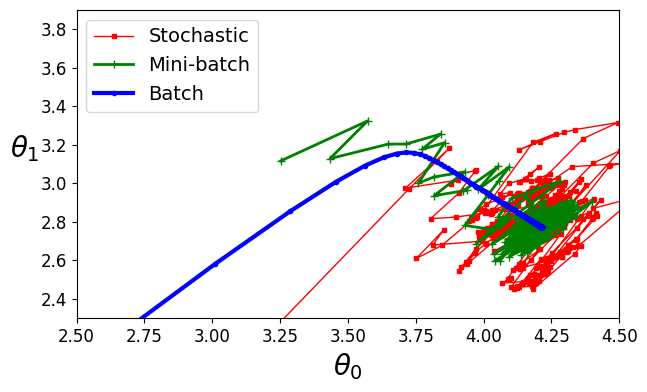

In [15]:
theta_path_bgd_arr = np.array(theta_path_bgd).reshape(-1, 2)
theta_path_sgd_arr = np.array(theta_path_sgd).reshape(-1, 2)
theta_path_mgd_arr = np.array(theta_path_mgd).reshape(-1, 2)

plt.figure(figsize=(7, 4))
plt.plot(theta_path_sgd_arr[:, 0], theta_path_sgd_arr[:, 1], "r-s", linewidth=1, markersize=3, label="Stochastic")
plt.plot(theta_path_mgd_arr[:, 0], theta_path_mgd_arr[:, 1], "g-+", linewidth=2, label="Mini-batch")
plt.plot(theta_path_bgd_arr[:, 0], theta_path_bgd_arr[:, 1], "b-o", linewidth=3, markersize=3, label="Batch")
plt.legend(loc="upper left", fontsize=14)
plt.xlabel(r"$\theta_0$", fontsize=20)
plt.ylabel(r"$\theta_1$   ", fontsize=20, rotation=0)
plt.axis([2.5, 4.5, 2.3, 3.9])
plt.show()

<div dir="rtl" style="text-align:right">

الـ 3 بيوصلوا قرب الـ minimum، لكن **Batch GD بيقف عند الـ minimum فعلًا**، أما Stochastic وMini-batch فبيفضلوا يمشوا حواليه. بس متنساش: Batch GD بياخد **وقت كبير في كل خطوة**، وكلهم كانوا هيوصلوا للـ minimum لو استخدمنا **learning schedule** كويس.

### مقارنة الخوارزميات لـ Linear Regression
($m$ = عدد العيّنات، $n$ = عدد الـ features)

| الخوارزمية | $m$ كبير | Out-of-core | $n$ كبير | Hyperparams | Scaling مطلوب | Scikit-Learn |
|---|---|---|---|---|---|---|
| **Normal Equation** | سريع | ❌ | **بطيء** | 0 | ❌ | `LinearRegression` |
| **Batch GD** | **بطيء** | ❌ | سريع | 2 | ✅ | n/a |
| **Stochastic GD** | سريع | ✅ | سريع | ≥ 2 | ✅ | `SGDRegressor` |
| **Mini-batch GD** | سريع | ✅ | سريع | ≥ 2 | ✅ | n/a |

> **بعد التدريب ما فيش فرق تقريبًا:** كل الخوارزميات دي بتنتهي بموديلات متشابهة جدًا وبتعمل predictions بنفس الطريقة بالظبط.
> والـ Normal Equation بتصلح لـ Linear Regression بس، أما Gradient Descent فبيتدرّب بيه **موديلات كتيرة** (هنشوف ده في الـ Neural Networks).

</div>

<div dir="rtl" style="text-align:right">

## 3) Polynomial Regression (الانحدار كثير الحدود)

إيه لو الداتا **أعقد** من خط مستقيم؟ المفاجأة: **ممكن نستخدم موديل خطي عشان نفهم داتا مش خطية!**

**الطريقة:** نضيف **قوى (powers)** كل feature كـ features جديدة، وبعدين ندرّب موديل خطي على المجموعة الموسّعة دي. ده اسمه **Polynomial Regression**.

نولّد داتا فيها علاقة تربيعية (quadratic) + noise:
$$y = 0.5x^2 + x + 2 + \text{noise}$$

</div>

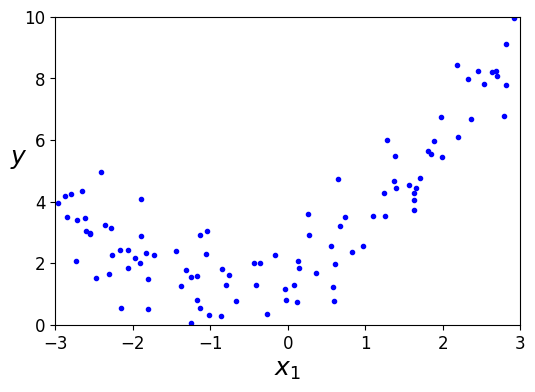

In [16]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X**2 + X + 2 + np.random.randn(m, 1)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])
plt.show()

<div dir="rtl" style="text-align:right">

واضح إن **خط مستقيم عمره ما هيطابق الداتا دي**. فنستخدم `PolynomialFeatures` عشان نضيف **مربع** كل feature (polynomial من الدرجة 2). هنا feature واحدة بس.

</div>

In [17]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)

print("X[0]      :", X[0])
print("X_poly[0] :", X_poly[0])     # [x , x²]

X[0]      : [-0.75275929]
X_poly[0] : [-0.75275929  0.56664654]


<div dir="rtl" style="text-align:right">

`X_poly` دلوقتي فيه الـ feature الأصلية **+ مربعها**. دلوقتي نعمل fit لـ `LinearRegression` على الداتا الموسّعة:

</div>

intercept: [1.78134581]  coef: [[0.93366893 0.56456263]]


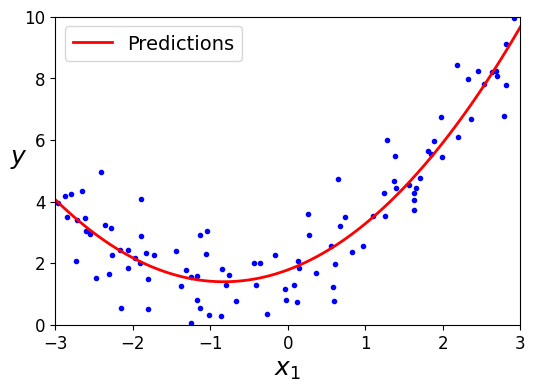

In [18]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
print("intercept:", lin_reg.intercept_, " coef:", lin_reg.coef_)

X_new = np.linspace(-3, 3, 100).reshape(100, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.legend(loc="upper left", fontsize=14)
plt.axis([-3, 3, 0, 10])
plt.show()

<div dir="rtl" style="text-align:right">

مش وحش! الموديل قدّر المعادلة قريبة من $0.5x^2 + 1.0x + 2.0$ (الأصلية)، والاختلاف البسيط بسبب الـ noise.

> **ميزة مهمة:** لما يبقى عندك **أكتر من feature**، Polynomial Regression **بيقدر يلاقي علاقات بين الـ features** (وده مش بيعمله Linear Regression العادي)، لأن `PolynomialFeatures` بيضيف **كل التركيبات** (combinations) حتى الدرجة المحددة.
> مثلًا لو عندك feature $a$ و$b$ و`degree=3`، هيضيف $a^2, a^3, b^2, b^3$ **وكمان** $ab, a^2b, ab^2$.

> ⚠️ **حذر من الانفجار التوافقي!** `PolynomialFeatures(degree=d)` بيحوّل $n$ features لـ $\frac{(n+d)!}{d!\,n!}$ feature. الرقم بيكبر بسرعة رهيبة.

</div>

In [19]:
from math import comb

# عدد الـ features بعد PolynomialFeatures (بدون الـ bias): C(n+d, d) - 1
for n_feat, d in [(2, 3), (10, 3), (100, 3), (100, 10)]:
    print(f"n={n_feat:>3}, degree={d:>2} -> {comb(n_feat + d, d) - 1:,} features")

n=  2, degree= 3 -> 9 features
n= 10, degree= 3 -> 285 features
n=100, degree= 3 -> 176,850 features
n=100, degree=10 -> 46,897,636,623,980 features


<div dir="rtl" style="text-align:right">

## 4) Learning Curves (منحنيات التعلم)

لو استخدمت Polynomial Regression بدرجة عالية، هتطابق الـ training data أحسن بكتير من Linear Regression العادي. شوف مقارنة بين موديل **خطي**، و**تربيعي** (درجة 2)، و**درجة 300**:

</div>

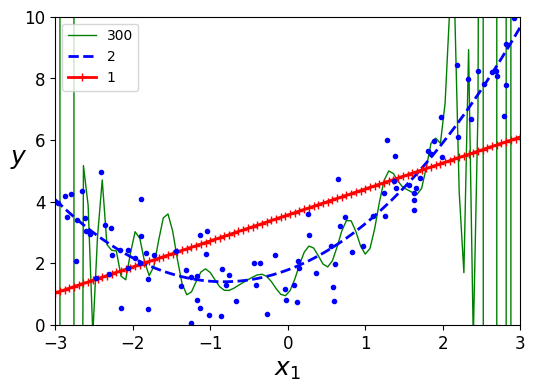

In [20]:
from sklearn.pipeline import Pipeline

plt.figure(figsize=(6, 4))

for style, width, degree in (("g-", 1, 300), ("b--", 2, 2), ("r-+", 2, 1)):
    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
        ("poly_features", polybig_features),
        ("std_scaler", std_scaler),
        ("lin_reg", lin_reg),
    ])
    polynomial_regression.fit(X, y)
    y_newbig = polynomial_regression.predict(X_new)
    plt.plot(X_new, y_newbig, style, label=str(degree), linewidth=width)

plt.plot(X, y, "b.", linewidth=3)
plt.legend(loc="upper left")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])
plt.show()

<div dir="rtl" style="text-align:right">

لاحظ إن موديل **درجة 300** بيتلوّى بشدة عشان يقرّب من كل نقطة تدريب.

- **درجة 300 ← Overfitting شديد** (حافظ الداتا بدل ما يتعلم منها).
- **الخطي ← Underfitting** (بسيط قوي على الداتا).
- **التربيعي ← أحسن موديل** هيعمّم (generalize) كويس. ده منطقي لأن الداتا اتولّدت من معادلة تربيعية.

**لكن في الواقع ما بنعرفش الدالة اللي ولّدت الداتا.** فإزاي نقرر الموديل المفروض يبقى معقّد قد إيه؟ وإزاي نعرف إنه Overfitting أو Underfitting؟

### الطريقة الأولى: Cross-Validation (من الفصل التاني)
- أداء **كويس** على الـ training و**وحش** في الـ cross-validation ← **Overfitting**.
- أداء **وحش** على الاتنين ← **Underfitting**.

### الطريقة التانية: Learning Curves 📈
**رسومات لأداء الموديل على الـ training set والـ validation set كدالة في حجم الـ training set.**
عشان نرسمها: ندرّب الموديل **كذا مرة** على أجزاء مختلفة الحجم من الـ training set.

</div>

In [21]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

def plot_learning_curves(model, X, y):
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=10)
    train_errors, val_errors = [], []
    for i in range(1, len(X_train) + 1):
        model.fit(X_train[:i], y_train[:i])
        y_train_predict = model.predict(X_train[:i])
        y_val_predict = model.predict(X_val)
        train_errors.append(mean_squared_error(y_train[:i], y_train_predict))
        val_errors.append(mean_squared_error(y_val, y_val_predict))
    plt.plot(np.sqrt(train_errors), "r-+", linewidth=2, label="train")
    plt.plot(np.sqrt(val_errors), "b-", linewidth=3, label="val")
    plt.legend(loc="upper right", fontsize=14)
    plt.xlabel("Training set size", fontsize=14)
    plt.ylabel("RMSE", fontsize=14)

<div dir="rtl" style="text-align:right">

### Learning curves لـ Linear Regression العادي (خط مستقيم)

</div>

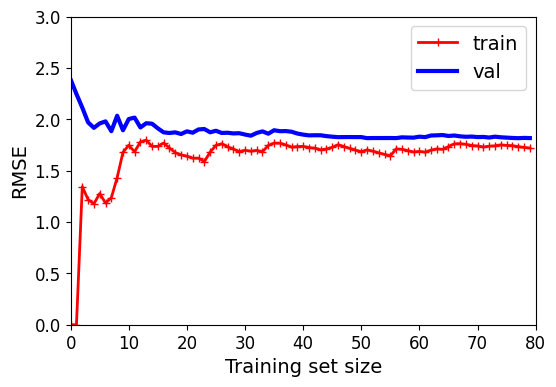

In [22]:
lin_reg = LinearRegression()

plt.figure(figsize=(6, 4))
plot_learning_curves(lin_reg, X, y)
plt.axis([0, 80, 0, 3])
plt.show()

<div dir="rtl" style="text-align:right">

**شرح المنحنيين:**

**الـ training error (الأحمر):**
- لما فيه عيّنة أو اتنين بس، الموديل يطابقهم **بالظبط**، عشان كده المنحنى **يبدأ من صفر**.
- كل ما نضيف عيّنات، يستحيل الموديل يطابق الداتا تمامًا (الداتا فيها noise وكمان **مش خطية أصلًا**) ← الـ error **بيزيد** لحد ما يوصل لـ **plateau** (هضبة)، وبعدها إضافة عيّنات ما بتغيرش كتير.

**الـ validation error (الأزرق):**
- لما الموديل بيتدرّب على عيّنات قليلة جدًا، مش بيقدر يعمّم، فالـ error **كبير** في الأول.
- كل ما يشوف أمثلة أكتر، **بيتعلم** فالـ error بينزل ببطء.
- بس برضه **خط مستقيم ما يقدرش** يمثّل الداتا كويس، فالـ error بيوقف عند plateau **قريب جدًا من المنحنى التاني**.

### 🔍 علامات الـ Underfitting
المنحنيين وصلوا لـ plateau، **قريبين من بعض** و**عاليين**.

> ⚠️ **لو الموديل بيعمل Underfitting، إضافة داتا تدريب أكتر مش هتفيد.** محتاج **موديل أعقد** أو **features أحسن**.

### Learning curves لموديل من الدرجة 10

</div>

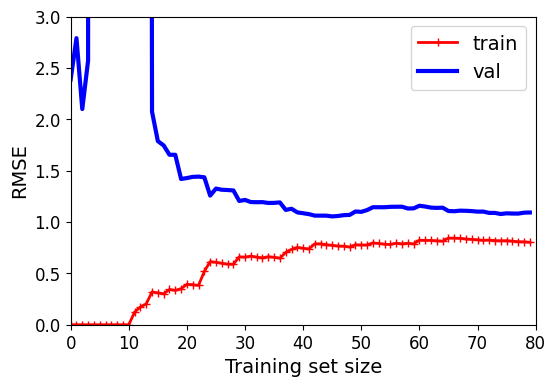

In [23]:
polynomial_regression = Pipeline([
    ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
    ("lin_reg", LinearRegression()),     # تعديل: الكتاب سمّاها "sgd_reg" بالغلط
])

plt.figure(figsize=(6, 4))
plot_learning_curves(polynomial_regression, X, y)
plt.axis([0, 80, 0, 3])
plt.show()

<div dir="rtl" style="text-align:right">

المنحنيات دي شبه اللي فاتت، لكن فيه **فرقين مهمين:**

1. **الـ error على الـ training data أقل بكتير** من Linear Regression.
2. **فيه فجوة (gap) بين المنحنيين.** يعني الموديل أحسن **بشكل ملحوظ** على الـ training data من الـ validation data، وده **علامة Overfitting**. لكن لو استخدمت training set أكبر بكتير، المنحنيين هيفضلوا يقرّبوا من بعض.

> 💡 **طريقة تحسين موديل بيعمل Overfitting:** أطعمه **داتا تدريب أكتر** لحد ما الـ validation error يوصل للـ training error.

</div>

<div dir="rtl" style="text-align:right">

### ⚖️ The Bias/Variance Tradeoff

نتيجة نظرية مهمة جدًا: **الـ generalization error لأي موديل = مجموع 3 أخطاء مختلفة تمامًا:**

| نوع الخطأ | سببه | النتيجة |
|---|---|---|
| **Bias** (الانحياز) | **افتراضات غلط**، مثلًا نفترض إن الداتا خطية وهي في الحقيقة تربيعية | موديل high-bias غالبًا بيعمل **Underfitting** |
| **Variance** (التباين) | **حساسية زيادة** للتغيّرات الصغيرة في الـ training data. موديل بدرجات حرية كتير (زي polynomial عالي) | موديل high-variance غالبًا بيعمل **Overfitting** |
| **Irreducible Error** | **الـ noise في الداتا نفسها** | الطريقة الوحيدة لتقليله: **تنضّف الداتا** (تصلّح مصادرها، تشيل الـ outliers) |

**الـ Tradeoff:**
- **زوّد تعقيد الموديل** ← الـ variance تزيد والـ bias تقل.
- **قلّل تعقيد الموديل** ← الـ bias تزيد والـ variance تقل.

عشان كده اسمها **tradeoff** (مقايضة).

> **تنبيه:** الـ bias هنا (الانحياز) **مش** هو الـ bias term ($\theta_0$) في الموديلات الخطية.

</div>

<div dir="rtl" style="text-align:right">

## 5) Regularized Linear Models (الموديلات الخطية المنتظَمة)

زي ما اتعلمنا، طريقة كويسة **لتقليل الـ Overfitting** هي **Regularization**: نقيّد الموديل. **كل ما قلّت درجات الحرية بتاعته، صعب عليه يعمل Overfitting.**

مثلًا: أبسط طريقة لعمل regularization لموديل polynomial هي **تقليل درجة الـ polynomial**.

**في الموديلات الخطية**، الـ regularization بيتم عادةً بـ **تقييد الأوزان (weights)**. هنشوف 3 طرق: **Ridge** و**Lasso** و**Elastic Net**.

نجهّز داتا صغيرة خطية تقريبًا للتجارب:

</div>

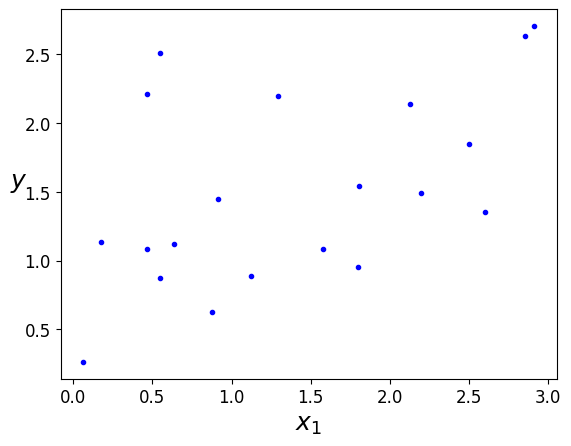

In [24]:
np.random.seed(42)
m_r = 20
X_r = 3 * np.random.rand(m_r, 1)
y_r = 1 + 0.5 * X_r + np.random.randn(m_r, 1) / 1.5
X_new_r = np.linspace(0, 3, 100).reshape(100, 1)

plt.plot(X_r, y_r, "b.")
plt.xlabel("$x_1$", fontsize=18); plt.ylabel("$y$", rotation=0, fontsize=18)
plt.show()

<div dir="rtl" style="text-align:right">

### 5.1) Ridge Regression (انحدار ريدج)

اسمها كمان **Tikhonov regularization**. هي نسخة منتظمة من Linear Regression: بنضيف **حد regularization** للـ cost function يساوي $\alpha \sum_{i=1}^{n} \theta_i^2$.

ده **بيجبر الـ algorithm** إنه مش بس يطابق الداتا، لكن كمان **يحافظ على الأوزان صغيرة قد الإمكان.**

> ⚠️ **حد الـ regularization بيتضاف للـ cost function وقت التدريب بس.** بعد التدريب، بنقيّم الموديل بمقياس الأداء **العادي** (من غير regularization).

**الـ hyperparameter $\alpha$** بيتحكم في قوة الـ regularization:
- $\alpha = 0$ ← Ridge = Linear Regression العادي.
- $\alpha$ **كبير جدًا** ← كل الأوزان قرب الصفر والنتيجة **خط مسطّح** بيعدّي في متوسط الداتا.

$$J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) + \frac{\alpha}{2} \sum_{i=1}^{n} \theta_i^2$$

**ملاحظات:**
- الـ bias term $\theta_0$ **مش بيتعمله regularization** (المجموع بيبدأ من $i=1$).
- لو $\mathbf{w}$ = vector الأوزان ($\theta_1$ لـ $\theta_n$)، فحد الـ regularization = $\frac{1}{2}\|\mathbf{w}\|_2^2$ حيث $\|\cdot\|_2$ هو **$\ell_2$ norm**.
- في Gradient Descent: ضيف $\alpha \mathbf{w}$ لـ gradient vector الـ MSE.

> ⚠️ **لازم تعمل scaling للداتا** (بـ `StandardScaler` مثلًا) قبل Ridge، لأنه **حسّاس لمقياس الـ features**. وده صحيح لمعظم الموديلات المنتظمة.

**الحل المباشر (closed-form):**
$$\hat{\boldsymbol{\theta}} = \left( \mathbf{X}^T \cdot \mathbf{X} + \alpha \mathbf{A} \right)^{-1} \cdot \mathbf{X}^T \cdot \mathbf{y}$$
حيث $\mathbf{A}$ هي مصفوفة الوحدة (identity) لكن بصفر في الخلية العليا الشمال (عشان الـ bias).

نرسم الموديلات بـ $\alpha$ مختلفة (الشمال: Ridge على داتا خطية، اليمين: polynomial درجة 10 + scaling + Ridge):

</div>

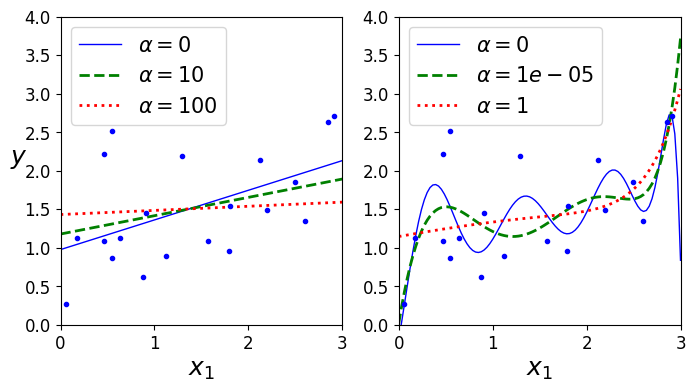

In [25]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

def plot_model(model_class, polynomial, alphas, **model_kargs):
    for alpha, style in zip(alphas, ("b-", "g--", "r:")):
        model = model_class(alpha=alpha, **model_kargs) if alpha > 0 else LinearRegression()
        if polynomial:
            model = Pipeline([
                ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
                ("std_scaler", StandardScaler()),
                ("regul_reg", model),
            ])
        model.fit(X_r, y_r)
        y_new_regul = model.predict(X_new_r)
        lw = 2 if alpha > 0 else 1
        plt.plot(X_new_r, y_new_regul, style, linewidth=lw, label=r"$\alpha = {}$".format(alpha))
    plt.plot(X_r, y_r, "b.", linewidth=3)
    plt.legend(loc="upper left", fontsize=15)
    plt.xlabel("$x_1$", fontsize=18)
    plt.axis([0, 3, 0, 4])

plt.figure(figsize=(8, 4))
plt.subplot(121)
plot_model(Ridge, polynomial=False, alphas=(0, 10, 100), random_state=42)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.subplot(122)
plot_model(Ridge, polynomial=True, alphas=(0, 10**-5, 1), random_state=42)
plt.show()

<div dir="rtl" style="text-align:right">

**لاحظ:** زيادة $\alpha$ بتخلّي الـ predictions **أكتر "تسطّحًا"** (أقل تطرّفًا وأكتر منطقية). ده **بيقلل الـ variance لكن بيزوّد الـ bias**.

نفس الشيء بنقدر نعمله إما بالحل المباشر (closed-form) أو بـ Gradient Descent، ونفس المزايا والعيوب.

**Ridge بحل Cholesky (closed-form):**

</div>

In [26]:
ridge_reg = Ridge(alpha=1, solver="cholesky", random_state=42)
ridge_reg.fit(X_r, y_r)
ridge_reg.predict([[1.5]])

array([1.55071465])

<div dir="rtl" style="text-align:right">

**و Ridge باستخدام Stochastic Gradient Descent:**

</div>

In [27]:
sgd_reg = SGDRegressor(penalty="l2", max_iter=1000, tol=1e-3, random_state=42)
sgd_reg.fit(X_r, y_r.ravel())
sgd_reg.predict([[1.5]])

array([1.47012588])

<div dir="rtl" style="text-align:right">

الـ hyperparameter **`penalty`** بيحدد نوع الـ regularization. `"l2"` معناها إن SGD هيضيف للـ cost function حدًّا يساوي **نص مربع $\ell_2$ norm** لـ vector الأوزان، وده ببساطة **Ridge Regression**.

</div>

<div dir="rtl" style="text-align:right">

### 5.2) Lasso Regression

**Least Absolute Shrinkage and Selection Operator Regression** (اتقصّرت لـ Lasso). نسخة تانية منتظمة من Linear Regression، بتضيف حد regularization للـ cost function، لكن بتستخدم **$\ell_1$ norm** (مجموع القيم المطلقة) بدل نص مربع $\ell_2$:

$$J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) + \alpha \sum_{i=1}^{n} |\theta_i|$$

### 🌟 الخاصية المهمة في Lasso
بتميل إنها **تلغي تمامًا أوزان الـ features الأقل أهمية** (تخليها **صفر**).
يعني Lasso **بتعمل Feature Selection تلقائيًا** وبتطلّع **sparse model** (موديل أغلب أوزانه أصفار).

</div>

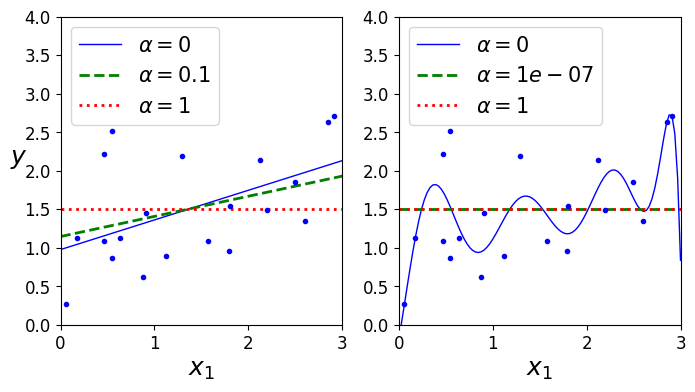

In [28]:
plt.figure(figsize=(8, 4))
plt.subplot(121)
plot_model(Lasso, polynomial=False, alphas=(0, 0.1, 1), random_state=42)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.subplot(122)
plot_model(Lasso, polynomial=True, alphas=(0, 10**-7, 1), tol=1, random_state=42)
plt.show()

<div dir="rtl" style="text-align:right">

الخط المتقطع في الرسمة اليمين ($\alpha = 10^{-7}$) بيبان **تربيعي وشبه خطي**: كل أوزان الـ features ذات الدرجات العالية **بقت صفر**.

نتأكد من الكلام ده بالأرقام: هنقارن **عدد الأوزان اللي بقت صفر** في Ridge مقابل Lasso على polynomial درجة 10:

</div>

In [29]:
poly_scaler = Pipeline([
    ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
    ("std_scaler", StandardScaler()),
])
X_r_poly = poly_scaler.fit_transform(X_r)

ridge = Ridge(alpha=1).fit(X_r_poly, y_r)
lasso = Lasso(alpha=0.05, max_iter=100000).fit(X_r_poly, y_r)

print("Ridge: عدد الأوزان = صفر تمامًا:", int(np.sum(ridge.coef_ == 0)), "من", ridge.coef_.size)
print("Lasso: عدد الأوزان = صفر تمامًا:", int(np.sum(lasso.coef_ == 0)), "من", lasso.coef_.size)
print()
print("أوزان Ridge:", np.round(ridge.coef_.ravel(), 2))
print("أوزان Lasso:", np.round(lasso.coef_.ravel(), 2))

Ridge: عدد الأوزان = صفر تمامًا: 0 من 10
Lasso: عدد الأوزان = صفر تمامًا: 8 من 10

أوزان Ridge: [ 0.19 -0.05 -0.05 -0.03 -0.    0.02  0.04  0.07  0.1   0.13]
أوزان Lasso: [0.11 0.   0.   0.   0.   0.   0.   0.   0.   0.27]


<div dir="rtl" style="text-align:right">

**Ridge** بيصغّر الأوزان لكن **ما بيصفّرهاش**، أما **Lasso** بيصفّر كتير منها.

**ليه كده؟** (بصريًا في Figure 4-19 في الكتاب): الـ $\ell_1$ penalty شكل خطوطها على هيئة **معيّن (diamond)** ورؤوسه على المحاور، فمسار Gradient Descent بيوصل لـ $\theta_1 = 0$ الأول وبعدين "يتدحرج في المجرى" لحد $\theta_2 = 0$. أما الـ $\ell_2$ penalty فخطوطها **دوائر**: الحل المنتظَم أقرب للصفر من غير المنتظَم لكن الأوزان **ما بتتلغيش بالكامل**.

> ⚠️ دالة Lasso **مش قابلة للاشتقاق** عند $\theta_i = 0$، لكن Gradient Descent لسه بيشتغل لو استخدمنا **subgradient vector** $\mathbf{g}$ بدل الـ gradient عند $\theta_i = 0$:
> $$g(\boldsymbol{\theta}, J) = \nabla_\theta \text{MSE}(\boldsymbol{\theta}) + \alpha \begin{pmatrix} \text{sign}(\theta_1) \\ \vdots \\ \text{sign}(\theta_n) \end{pmatrix}, \quad \text{sign}(\theta_i) = \begin{cases} -1 & \theta_i < 0 \\ 0 & \theta_i = 0 \\ +1 & \theta_i > 0 \end{cases}$$
> ومسار BGD بيميل **يتنطّط عبر المجرى** قرب الآخر لأن الميل بيتغير فجأة عند $\theta_2 = 0$، فلازم تقلّل الـ learning rate تدريجيًا عشان يتقارب فعلًا.

</div>

In [30]:
lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X_r, y_r)
lasso_reg.predict([[1.5]])

array([1.53788174])

<div dir="rtl" style="text-align:right">

(وتقدر تستخدم بدلها `SGDRegressor(penalty="l1")`.)

### 5.3) Elastic Net

**حل وسط بين Ridge وLasso.** حد الـ regularization هو **خليط بسيط** من حدّي Ridge وLasso، وبتتحكم في نسبة الخلط $r$:
- $r = 0$ ← Elastic Net = **Ridge**.
- $r = 1$ ← Elastic Net = **Lasso**.

$$J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) + r\alpha \sum_{i=1}^{n} |\theta_i| + \frac{1-r}{2} \alpha \sum_{i=1}^{n} \theta_i^2$$

</div>

In [31]:
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)   # l1_ratio هو r
elastic_net.fit(X_r, y_r)
elastic_net.predict([[1.5]])

array([1.54333232])

<div dir="rtl" style="text-align:right">

### 🧭 إمتى أستخدم إيه؟

| الموديل | امتى |
|---|---|
| **Linear Regression** العادي | **تجنّبه تقريبًا دايمًا.** الأفضل يبقى فيه **شوية regularization على الأقل**. |
| **Ridge** | **اختيار افتراضي كويس.** |
| **Lasso** | لو **متوقع إن features قليلة بس هي المفيدة** (بيصفّر الأوزان عديمة الفايدة). |
| **Elastic Net** | **غالبًا أفضل من Lasso**، لأن Lasso **بيتصرف بشكل غير منتظم** لما عدد الـ features **أكبر من** عدد العيّنات، أو لما فيه features **مرتبطة ببعض بقوة** (correlated). |

</div>

<div dir="rtl" style="text-align:right">

### 5.4) Early Stopping (الإيقاف المبكر)

طريقة **مختلفة تمامًا** للـ regularization في الخوارزميات التكرارية (زي Gradient Descent): **وقّف التدريب بمجرد ما الـ validation error يوصل لأقل قيمة.**

**إزاي بتشتغل؟** مع كل epoch:
- الـ error على الـ **training set** بينزل طبيعي.
- الـ error على الـ **validation set** بينزل كمان... لحد نقطة معيّنة **بيقف عن النزول وبيبدأ يطلع تاني**. ده معناه إن الموديل **بدأ يعمل Overfitting**.
- **Early stopping:** وقّف لما الـ validation error يوصل للـ minimum.

جيوفري هينتون سمّاها **"beautiful free lunch"** (غدا مجاني جميل)، لأنها بسيطة وفعّالة جدًا.

> مع Stochastic وMini-batch GD المنحنيات **مش ناعمة** وممكن يصعب تعرف وصلت للـ minimum ولا لأ. الحل: **وقّف بس بعد ما الـ validation error يبقى أعلى من الـ minimum لفترة** (لما تبقى واثق إن الموديل مش هيتحسّن)، وبعدين **ارجع بالـ parameters** للنقطة اللي كان فيها الـ validation error أقل ما يمكن.

نطبّق ده على polynomial عالي الدرجة (90) مع SGD:

</div>

In [32]:
from copy import deepcopy

np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 2 + X + 0.5 * X**2 + np.random.randn(m, 1)

X_train, X_val, y_train, y_val = train_test_split(X[:50], y[:50].ravel(), test_size=0.5, random_state=10)

poly_scaler = Pipeline([
    ("poly_features", PolynomialFeatures(degree=90, include_bias=False)),
    ("std_scaler", StandardScaler()),
])
X_train_poly_scaled = poly_scaler.fit_transform(X_train)
X_val_poly_scaled = poly_scaler.transform(X_val)

# max_iter=1 + warm_start=True  =>  كل fit() بتكمّل من حيث وقفت (epoch واحدة)
sgd_reg = SGDRegressor(max_iter=1, tol=None, warm_start=True, penalty=None,
                       learning_rate="constant", eta0=0.0005, random_state=42)

minimum_val_error = float("inf")
best_epoch = None
best_model = None
train_errors, val_errors = [], []

for epoch in range(1000):
    sgd_reg.fit(X_train_poly_scaled, y_train)
    y_train_predict = sgd_reg.predict(X_train_poly_scaled)
    y_val_predict = sgd_reg.predict(X_val_poly_scaled)
    train_errors.append(mean_squared_error(y_train, y_train_predict))
    val_error = mean_squared_error(y_val, y_val_predict)
    val_errors.append(val_error)
    if val_error < minimum_val_error:
        minimum_val_error = val_error
        best_epoch = epoch
        # تعديل: الكتاب بيستخدم clone() وده بينسخ الموديل "فاضي" من غير الأوزان المتدرّبة!
        # deepcopy بينسخ الموديل بأوزانه الحالية
        best_model = deepcopy(sgd_reg)

print("best epoch:", best_epoch, " min val RMSE:", np.sqrt(minimum_val_error))

best epoch: 239  min val RMSE: 1.1624590535779686


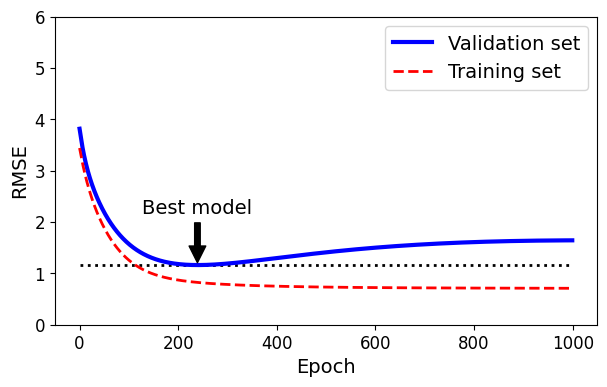

In [33]:
best_val_rmse = np.sqrt(minimum_val_error)

plt.figure(figsize=(7, 4))
plt.annotate("Best model", xy=(best_epoch, best_val_rmse),
             xytext=(best_epoch, best_val_rmse + 1),
             ha="center", arrowprops=dict(facecolor="black", shrink=0.05), fontsize=14)
plt.plot([0, 1000], [best_val_rmse, best_val_rmse], "k:", linewidth=2)
plt.plot(np.sqrt(val_errors), "b-", linewidth=3, label="Validation set")
plt.plot(np.sqrt(train_errors), "r--", linewidth=2, label="Training set")
plt.legend(loc="upper right", fontsize=14)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("RMSE", fontsize=14)
plt.ylim(0, 6)
plt.show()

<div dir="rtl" style="text-align:right">

الـ training error (الأحمر) بينزل باستمرار، أما الـ validation error (الأزرق) **بينزل لحد نقطة وبعدين بيرجع يطلع** ← بداية الـ Overfitting. **الـ best model** هو اللي عند أقل validation error.

> ملحوظة: `warm_start=True` معناها لما نستدعي `fit()` تكمّل التدريب من حيث وقفت بدل ما تبدأ من الصفر.

</div>

<div dir="rtl" style="text-align:right">

## 6) Logistic Regression (الانحدار اللوجستي)

زي ما قلنا في الفصل الأول، بعض خوارزميات الـ regression **تُستخدم للتصنيف** كمان. **Logistic Regression** (أو Logit Regression) بتُستخدم عادةً **لتقدير احتمال** إن عيّنة تنتمي لفئة معينة (مثلًا: إيه احتمال إن الإيميل ده spam؟).

- لو الاحتمال المقدّر **أكبر من 50%** ← الموديل يتوقع إنها **من الفئة الـ positive** (label = 1).
- غير كده ← الفئة الـ negative (label = 0).

يعني هو **binary classifier**.

### 6.1) Estimating Probabilities (تقدير الاحتمالات)

زي Linear Regression، بيحسب **مجموع موزون للـ features + bias**، لكن بدل ما يطلّع النتيجة مباشرة، بيطلّع **الـ logistic** بتاعها:

$$\hat{p} = h_\theta(\mathbf{x}) = \sigma\left( \boldsymbol{\theta}^T \cdot \mathbf{x} \right)$$

الـ **logistic** (أو logit) $\sigma(\cdot)$ هي **sigmoid function** (شكلها حرف S) بتطلّع رقم **بين 0 و 1**:

$$\sigma(t) = \frac{1}{1 + \exp(-t)}$$

</div>

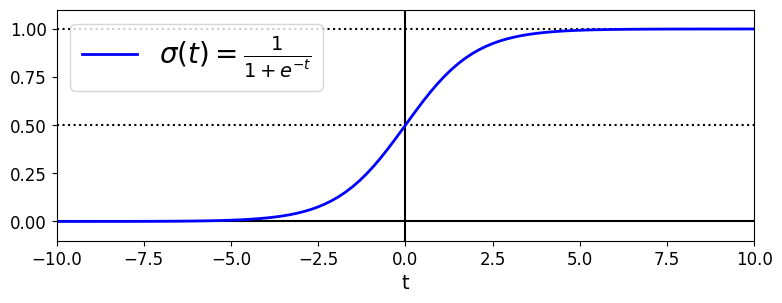

In [34]:
t = np.linspace(-10, 10, 100)
sig = 1 / (1 + np.exp(-t))

plt.figure(figsize=(9, 3))
plt.plot([-10, 10], [0, 0], "k-")
plt.plot([-10, 10], [0.5, 0.5], "k:")
plt.plot([-10, 10], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \frac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left", fontsize=20)
plt.axis([-10, 10, -0.1, 1.1])
plt.show()

<div dir="rtl" style="text-align:right">

بعد ما الموديل يقدّر الاحتمال $\hat{p}$، التوقع سهل:

$$\hat{y} = \begin{cases} 0 & \text{if } \hat{p} < 0.5 \\ 1 & \text{if } \hat{p} \geq 0.5 \end{cases}$$

لاحظ إن $\sigma(t) < 0.5$ لما $t < 0$، و$\sigma(t) \geq 0.5$ لما $t \geq 0$. فالموديل **بيتوقع 1 لو $\boldsymbol{\theta}^T \cdot \mathbf{x}$ موجب، و0 لو سالب.**

### 6.2) Training and Cost Function

**هدف التدريب:** نضبط $\boldsymbol{\theta}$ بحيث الموديل يقدّر **احتمالات عالية** للعيّنات الـ positive ($y=1$)، و**احتمالات منخفضة** للـ negative ($y=0$).

الـ cost لعيّنة واحدة:

$$c(\boldsymbol{\theta}) = \begin{cases} -\log(\hat{p}) & \text{if } y = 1 \\ -\log(1 - \hat{p}) & \text{if } y = 0 \end{cases}$$

**ليه منطقية؟** لأن $-\log(t)$:
- **بتكبر جدًا** لما $t$ يقرّب من 0 ← الـ cost **كبير** لو الموديل قدّر احتمال قريب من 0 لعيّنة positive (غلط فادح).
- **قريبة من 0** لما $t$ يقرّب من 1 ← الـ cost **قريب من صفر** لو الاحتمال قريب من 1 لعيّنة positive (ده المطلوب).

</div>

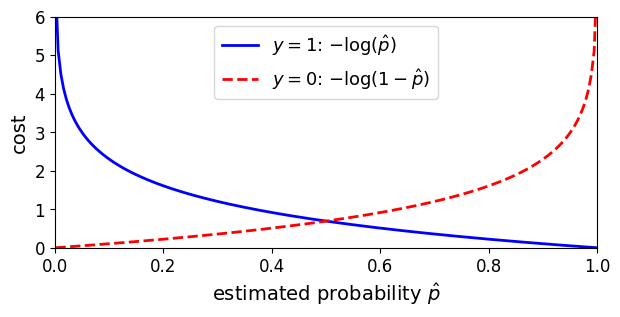

In [35]:
p = np.linspace(0.001, 0.999, 200)

plt.figure(figsize=(7, 3))
plt.plot(p, -np.log(p), "b-", linewidth=2, label=r"$y=1$: $-\log(\hat{p})$")
plt.plot(p, -np.log(1 - p), "r--", linewidth=2, label=r"$y=0$: $-\log(1-\hat{p})$")
plt.xlabel(r"estimated probability $\hat{p}$")
plt.ylabel("cost")
plt.legend(fontsize=13)
plt.axis([0, 1, 0, 6])
plt.show()

<div dir="rtl" style="text-align:right">

الـ cost على الـ training set كله هي **المتوسط** على كل العيّنات. وبتتكتب في معادلة واحدة اسمها **log loss**:

$$J(\boldsymbol{\theta}) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log\left(\hat{p}^{(i)}\right) + \left(1 - y^{(i)}\right) \log\left(1 - \hat{p}^{(i)}\right) \right]$$

**الخبر الوحش:** مفيش معادلة مباشرة (closed-form) تحسب $\boldsymbol{\theta}$ المثالية هنا (مفيش حاجة زي Normal Equation).

**الخبر الحلو:** الـ cost function **convex**، فـ Gradient Descent **مضمون** يلاقي الـ global minimum (لو الـ learning rate مش كبير واستنيت كفاية). والـ partial derivatives:

$$\frac{\partial}{\partial \theta_j} J(\boldsymbol{\theta}) = \frac{1}{m} \sum_{i=1}^{m} \left( \sigma\left(\boldsymbol{\theta}^T \cdot \mathbf{x}^{(i)}\right) - y^{(i)} \right) x_j^{(i)}$$

المعادلة دي **شبه المعادلة بتاعة Linear Regression** تقريبًا: لكل عيّنة بتحسب **خطأ التوقع** وتضربه في قيمة الـ feature رقم j، وبعدين تاخد المتوسط. وبعد كده تستخدم الـ gradient vector في **Batch GD**. (ولـ SGD تاخد عيّنة واحدة، ولـ Mini-batch تاخد دفعة.)

</div>

In [36]:
# تطبيق مباشر: Logistic Regression بـ Batch GD من الصفر على داتا بسيطة
from sklearn import datasets
iris = datasets.load_iris()

xs = iris["data"][:, 3:]                           # petal width
ys = (iris["target"] == 2).astype(int).reshape(-1, 1)
Xb_ = np.c_[np.ones((len(xs), 1)), xs]

def sigmoid(z): return 1 / (1 + np.exp(-z))

theta_lr = np.zeros((2, 1))
eta, mm = 0.5, len(Xb_)
for it in range(20000):
    p_hat = sigmoid(Xb_.dot(theta_lr))
    grad = 1/mm * Xb_.T.dot(p_hat - ys)         # نفس المعادلة اللي فوق
    theta_lr -= eta * grad

p_hat = sigmoid(Xb_.dot(theta_lr))
log_loss = -np.mean(ys * np.log(p_hat) + (1 - ys) * np.log(1 - p_hat))
print("theta:", theta_lr.ravel(), " log loss:", log_loss)

theta: [-20.44783952  12.52934494]  log loss: 0.11147742689558764


<div dir="rtl" style="text-align:right">

### 6.3) Decision Boundaries (حدود القرار)

هنستخدم داتا **Iris** الشهيرة: فيها طول وعرض **الـ sepal** و**الـ petal** لـ 150 زهرة من 3 أنواع: Iris-Setosa وIris-Versicolor وIris-Virginica.

هنبني classifier يكتشف **Iris-Virginica** بالاعتماد على **عرض الـ petal** بس.

</div>

In [37]:
from sklearn.linear_model import LogisticRegression

print(list(iris.keys()))

X = iris["data"][:, 3:]                       # petal width
y = (iris["target"] == 2).astype(int)         # تعديل: np.int اتشالت، نستخدم int
                                              # 1 لو Iris-Virginica، وإلا 0

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X, y)

['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

<div dir="rtl" style="text-align:right">

نشوف الاحتمالات المقدّرة لأزهار بعرض petal من 0 لـ 3 سم:

</div>

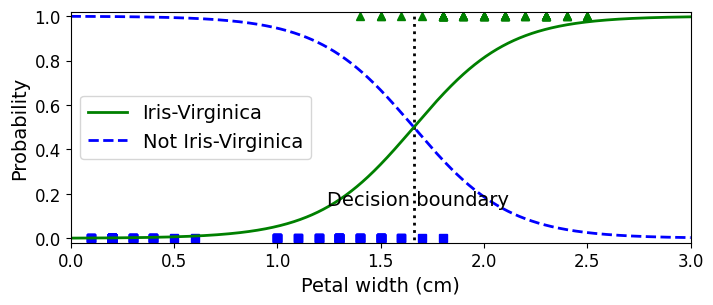

Decision boundary: 1.6606606606606606


In [38]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]   # رقم واحد (scalar)

plt.figure(figsize=(8, 3))
plt.plot(X[y == 0], y[y == 0], "bs")
plt.plot(X[y == 1], y[y == 1], "g^")
plt.plot([decision_boundary, decision_boundary], [-1, 2], "k:", linewidth=2)
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris-Virginica")
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="Not Iris-Virginica")
plt.text(decision_boundary + 0.02, 0.15, "Decision boundary", fontsize=14, color="k", ha="center")
plt.xlabel("Petal width (cm)", fontsize=14)
plt.ylabel("Probability", fontsize=14)
plt.legend(loc="center left", fontsize=14)
plt.axis([0, 3, -0.02, 1.02])
plt.show()

print("Decision boundary:", decision_boundary)

<div dir="rtl" style="text-align:right">

**شرح الرسمة:**
- عرض petal **Iris-Virginica** (المثلثات) من **1.4 لـ 2.5 سم**، والأنواع التانية (المربعات) غالبًا أصغر، من 0.1 لـ 1.8 سم. فيه **تداخل بسيط**.
- **فوق 2 سم تقريبًا** الـ classifier **واثق جدًا** إنها Virginica. **تحت 1 سم** واثق جدًا إنها مش Virginica. **في النص** مش متأكد.
- لو طلبت `predict()` (مش `predict_proba()`) هيرجّع **الفئة الأكثر احتمالًا**. فيه **decision boundary** عند حوالي **1.6 سم** حيث الاحتمالين = 50%: أكبر من 1.6 ← Virginica، غير كده ← لأ (حتى لو مش واثق قوي).

</div>

In [39]:
log_reg.predict([[1.7], [1.5]])

array([1, 0])

<div dir="rtl" style="text-align:right">

### Decision boundary بـ feature اتنين (طول وعرض الـ petal)

بعد التدريب، الـ classifier بيقدّر احتمال إن زهرة جديدة Virginica. **الخط المتقطع = decision boundary (احتمال 50%)**، وهو **خط مستقيم** (linear boundary). كل خط متوازي بيمثّل احتمال معيّن (من 15% لـ 90%).

</div>

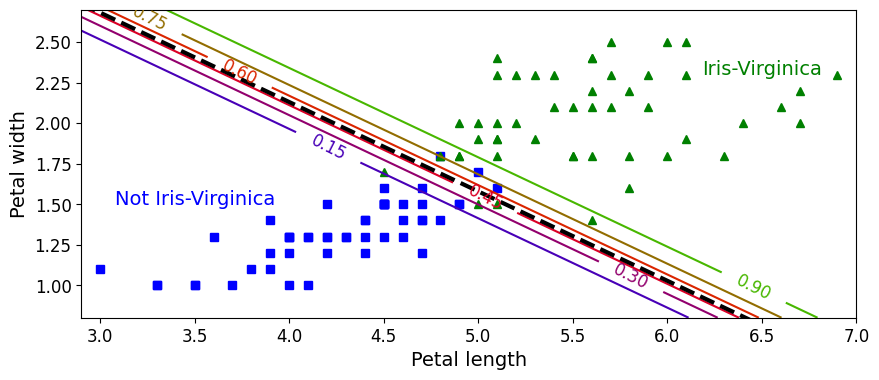

In [40]:
X = iris["data"][:, (2, 3)]                  # petal length, petal width
y = (iris["target"] == 2).astype(int)

log_reg = LogisticRegression(C=10**10, random_state=42)   # C كبير = تقريبًا من غير regularization
log_reg.fit(X, y)

x0, x1 = np.meshgrid(np.linspace(2.9, 7, 500).reshape(-1, 1),
                     np.linspace(0.8, 2.7, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]
y_proba = log_reg.predict_proba(X_new)

plt.figure(figsize=(10, 4))
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs")
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^")

zz = y_proba[:, 1].reshape(x0.shape)
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)

left_right = np.array([2.9, 7])
boundary = -(log_reg.coef_[0][0] * left_right + log_reg.intercept_[0]) / log_reg.coef_[0][1]

plt.clabel(contour, inline=1, fontsize=12)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.5, "Not Iris-Virginica", fontsize=14, color="b", ha="center")
plt.text(6.5, 2.3, "Iris-Virginica", fontsize=14, color="g", ha="center")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.axis([2.9, 7, 0.8, 2.7])
plt.show()

<div dir="rtl" style="text-align:right">

زي باقي الموديلات الخطية، Logistic Regression ممكن تتعمل ليها **regularization** بـ $\ell_1$ أو $\ell_2$. و scikit-learn **بتضيف $\ell_2$ penalty افتراضيًا.**

> ⚠️ **الـ hyperparameter اللي بيتحكم في قوة الـ regularization في `LogisticRegression` مش `alpha`** (زي باقي الموديلات الخطية) لكن **مقلوبه: `C`**.
> **كل ما `C` كبر، الـ regularization بتقل.**

### 6.4) Softmax Regression (الانحدار Softmax)

Logistic Regression ممكن تتعمّم لتدعم **عدة فئات مباشرة** من غير ما نحتاج ندرّب ونجمّع كذا binary classifier (زي ما شفنا في الفصل التالت). ده اسمه **Softmax Regression** أو **Multinomial Logistic Regression**.

**الفكرة:** لما نديله عيّنة $\mathbf{x}$:
1. يحسب **score** لكل فئة $k$:
$$s_k(\mathbf{x}) = \boldsymbol{\theta}_k^T \cdot \mathbf{x}$$
(كل فئة ليها **parameter vector** خاص بيها، وبيتخزنوا كـ **صفوف** في مصفوفة $\boldsymbol{\Theta}$).

2. يقدّر احتمال كل فئة بتطبيق **softmax function** (أو normalized exponential) على الـ scores: **ياخد exp لكل score وبعدين يعمل normalize بالقسمة على مجموع الـ exps**:
$$\hat{p}_k = \sigma(\mathbf{s}(\mathbf{x}))_k = \frac{\exp(s_k(\mathbf{x}))}{\sum_{j=1}^{K} \exp(s_j(\mathbf{x}))}$$
حيث $K$ = عدد الفئات.

3. بيتوقّع **الفئة صاحبة أعلى احتمال** (وهي نفسها أعلى score):
$$\hat{y} = \underset{k}{\operatorname{argmax}}\; \sigma(\mathbf{s}(\mathbf{x}))_k = \underset{k}{\operatorname{argmax}}\; s_k(\mathbf{x})$$
(`argmax` بيرجّع قيمة المتغير اللي بتعظّم الدالة.)

> ⚠️ **Softmax Regression بيتوقع فئة واحدة في المرة** (multiclass، مش multioutput)، فاستخدمه بس مع **فئات متنافية** (mutually exclusive) زي أنواع النباتات. **ما تستخدمهوش** عشان تتعرّف على **أكتر من شخص في صورة واحدة**.

</div>

In [41]:
# softmax بإيدينا عشان نفهمها
def softmax(scores):
    exps = np.exp(scores - scores.max())     # بنطرح الأكبر عشان الثبات العددي
    return exps / exps.sum()

scores = np.array([2.0, 1.0, 0.1])
print("scores       :", scores)
print("probabilities:", np.round(softmax(scores), 3), " مجموعها =", softmax(scores).sum())

scores       : [2.  1.  0.1]
probabilities: [0.659 0.242 0.099]  مجموعها = 1.0


<div dir="rtl" style="text-align:right">

**لاحظ:** الـ scores الأعلى ليها احتمالات أعلى، والاحتمالات **مجموعها 1**.

### التدريب: Cross Entropy
الهدف: موديل يقدّر **احتمال عالي للفئة الصح** (وبالتالي احتمال منخفض للباقي). تقليل **cross entropy** بيحقق ده لأنها **بتعاقب الموديل لما يقدّر احتمال منخفض للفئة الصح**:

$$J(\boldsymbol{\Theta}) = -\frac{1}{m} \sum_{i=1}^{m} \sum_{k=1}^{K} y_k^{(i)} \log\left(\hat{p}_k^{(i)}\right)$$

حيث $y_k^{(i)} = 1$ لو الفئة الصحيحة للعيّنة $i$ هي $k$، وإلا 0.

لما يبقى عندنا **فئتين بس ($K=2$)**، الـ cost function دي **تساوي log loss** بتاعة Logistic Regression.

> ### 📡 Cross Entropy: من نظرية المعلومات
> تخيّل إنك عايز تبعت معلومات الطقس كل يوم بكفاءة. لو فيه 8 احتمالات (مشمس، ممطر...) تقدر تكوّد كل واحد بـ **3 bits** ($2^3 = 8$).
> لكن لو **متوقع إنه مشمس تقريبًا كل يوم**، أكفأ إنك تكوّد "مشمس" بـ **bit واحد (0)** وباقي الـ 7 بـ **4 bits** (بتبدأ بـ 1).
> **Cross entropy بتقيس متوسط عدد الـ bits اللي بتبعتها فعلًا لكل احتمال.**
> - لو توقعاتك مثالية: cross entropy = **entropy** الطقس نفسه (عدم القابلية للتنبؤ الذاتية).
> - لو توقعاتك غلط (مثلًا بتمطر كتير): cross entropy **أكبر** بمقدار اسمه **Kullback–Leibler divergence**.
>
> Cross entropy بين توزيعين احتماليين $p$ و$q$: $H(p, q) = -\sum_x p(x) \log q(x)$.

والـ **gradient vector** للفئة $k$:

$$\nabla_{\theta_k} J(\boldsymbol{\Theta}) = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{p}_k^{(i)} - y_k^{(i)} \right) \mathbf{x}^{(i)}$$

دلوقتي نحسب الـ gradient لكل فئة، ونستخدم Gradient Descent لإيجاد $\boldsymbol{\Theta}$ اللي بتقلّل الـ cost.

#### Softmax Regression على Iris بـ 3 فئات

</div>

In [42]:
X = iris["data"][:, (2, 3)]        # petal length, petal width
y = iris["target"]

# تعديل: الكتاب بيحدد multi_class="multinomial" وده اتشال/بقى deprecated.
# في scikit-learn الحديثة، LogisticRegression مع solver="lbfgs" بيعمل Softmax تلقائيًا
# لما يبقى فيه أكتر من فئتين.
softmax_reg = LogisticRegression(solver="lbfgs", C=10, random_state=42)
softmax_reg.fit(X, y)

print("predict       :", softmax_reg.predict([[5, 2]]))
print("probabilities :", np.round(softmax_reg.predict_proba([[5, 2]]), 4))

predict       : [2]
probabilities : [[0.     0.0574 0.9426]]


<div dir="rtl" style="text-align:right">

لو لقيت زهرة iris بـ petal **5 سم طول و2 سم عرض**، الموديل هيقولك إنها **Iris-Virginica (فئة 2)** باحتمال حوالي **94%** (أو Iris-Versicolor باحتمال حوالي 6%).

#### رسم الـ decision boundaries

</div>

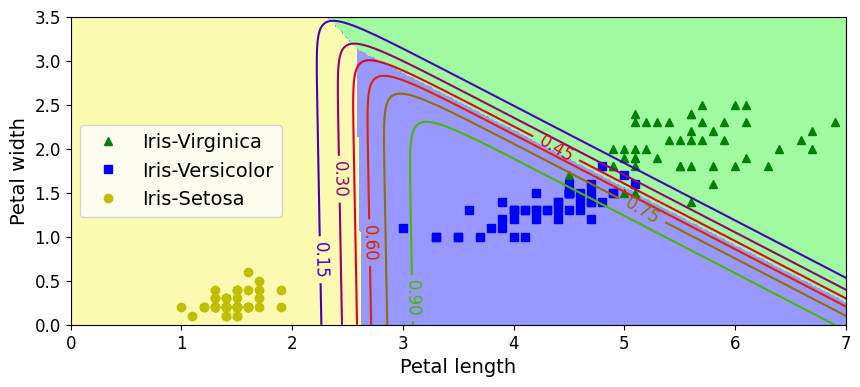

In [43]:
from matplotlib.colors import ListedColormap

x0, x1 = np.meshgrid(np.linspace(0, 8, 500).reshape(-1, 1),
                     np.linspace(0, 3.5, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])

plt.figure(figsize=(10, 4))
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris-Virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris-Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris-Setosa")
contour = plt.contour(x0, x1, zz1, cmap=plt.cm.brg)
plt.clabel(contour, inline=1, fontsize=12)
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="center left", fontsize=14)
plt.axis([0, 7, 0, 3.5])
plt.show()

<div dir="rtl" style="text-align:right">

**ملاحظات على الرسمة:**
- حدود القرار بين أي فئتين **خطية** (خطوط مستقيمة).
- الخطوط المنحنية = **احتمالات فئة Iris-Versicolor** (مثلًا الخط المكتوب عليه 0.450 = حد احتمال 45%).
- الموديل **ممكن يتوقع فئة احتمالها أقل من 50%**. مثلًا عند النقطة اللي كل حدود القرار بتتقابل فيها، كل الفئات بتاخد احتمال **33%** متساوي.

</div>

<div dir="rtl" style="text-align:right">

## 7) ملخص الفصل (Cheat Sheet)

### الموديلات
| الموديل | النوع | الـ Cost Function | التدريب |
|---|---|---|---|
| **Linear Regression** | Regression | MSE | Normal Equation أو GD |
| **Polynomial Regression** | Regression | MSE (على features موسّعة) | زي Linear Regression |
| **Ridge** | Regression | MSE + $\frac{\alpha}{2}\sum\theta_i^2$ | closed-form أو GD |
| **Lasso** | Regression | MSE + $\alpha\sum\lvert\theta_i\rvert$ | GD (subgradient) / coordinate descent |
| **Elastic Net** | Regression | MSE + خليط Ridge/Lasso | زي Lasso |
| **Logistic Regression** | تصنيف (فئتين) | Log loss | GD فقط (مفيش closed-form) |
| **Softmax Regression** | تصنيف (عدة فئات) | Cross entropy | GD فقط |

### أنواع Gradient Descent
| النوع | يستخدم في كل خطوة | الميزة | العيب |
|---|---|---|---|
| **Batch** | الداتا كلها | مسار منتظم، بيستقر عند الـ minimum | بطيء على الداتا الكبيرة |
| **Stochastic** | عيّنة واحدة | سريع، بيهرب من local minima، out-of-core | عشوائي، ما بيستقرش |
| **Mini-batch** | دفعة صغيرة | توازن، بيستغل الـ GPU | ممكن يعلق في local minima |

### أهم الدروس 🎯
1. **Normal Equation** = حل مباشر لكن **بطيء لما الـ features تكتر**. **Gradient Descent** = تقريبي لكن **بيتعامل مع features كتير وداتا ضخمة**.
2. **Feature Scaling ضروري** لـ Gradient Descent ولكل الموديلات المنتظمة (Ridge/Lasso...).
3. **Learning rate:** صغير ← بطيء، كبير ← يتباعد.
4. **Learning curves**: الفجوة بين المنحنيين = Overfitting. المنحنيين عاليين وقريبين = Underfitting.
5. **Bias/Variance tradeoff:** تعقيد أكتر ← bias أقل وvariance أعلى.
6. **Regularization** (Ridge/Lasso/Elastic Net/Early Stopping) بتقلل الـ Overfitting. **Ridge** افتراضي، **Lasso** لـ feature selection، **Elastic Net** غالبًا أحسن من Lasso.
7. **Logistic** = sigmoid + log loss. **Softmax** = softmax + cross entropy. **C** في scikit-learn هو **مقلوب** قوة الـ regularization.

</div>

<div dir="rtl" style="text-align:right">

## 8) التمارين (Exercises) مع الإجابات

**1) إيه خوارزمية تدريب Linear Regression اللي ممكن أستخدمها لو عندي training set فيه ملايين الـ features؟**

ممكن تستخدم **Batch GD** أو **Stochastic GD** أو **Mini-batch GD**. الـ **Normal Equation** مش هتنفع لأنها **بتبطأ جدًا** لما عدد الـ features يكبر (وكمان محتاجة ذاكرة ضخمة). لو الـ training set بيتحمّل في الذاكرة، Batch GD كويس، ولو لأ استخدم SGD أو Mini-batch.

---
**2) لو الـ features في الـ training set مقاييسها مختلفة جدًا، إيه الخوارزميات اللي هتتأثر وإزاي؟ وأعمل إيه؟**

خوارزميات **Gradient Descent** (وأي موديل منتظَم) هتتأثر: الـ cost function هتبقى **وعاء متطاول**، فـ GD هياخد **وقت طويل** عشان يتقارب. والموديلات المنتظمة ممكن تتقارب لحل **غير مثالي** لأن الـ regularization بتعاقب الأوزان الكبيرة، فالـ features اللي قيمها صغيرة بتتجاهل مقارنةً بالكبيرة.
**الحل:** اعمل **scaling** (مثلًا `StandardScaler`). والـ **Normal Equation** مش بتتأثر.

---
**3) هل Gradient Descent ممكن يتعلق في local minimum وهو بيدرّب Logistic Regression؟**

**لأ**، لأن الـ cost function (log loss) **convex**: فيه **global minimum واحد** وما فيش local minima.

---
**4) هل كل خوارزميات Gradient Descent بتوصل لنفس الموديل لو سيبتها تشتغل كفاية؟**

**مش بالظبط.** لو الـ cost convex، فهي كلها هتنتهي بموديلات **متشابهة جدًا**، لكن **Stochastic وMini-batch مش هيتقاربوا فعليًا** (هيفضلوا يتنطّطوا حوالين الـ optimum) إلا لو **قلّلت الـ learning rate تدريجيًا**. فحتى لو سيبتهم وقت طويل جدًا، هيدّوا موديلات **مختلفة شوية**.

---
**5) استخدمت Batch GD ورسمت الـ validation error كل epoch، ولاحظت إنه بيزيد باستمرار. إيه اللي بيحصل غالبًا؟ وإزاي أصلحه؟**

- **احتمال 1:** الـ **learning rate كبير** والـ algorithm **بيتباعد**. لو كمان الـ **training error** بيزيد، ده هو السبب ← **قلّل الـ learning rate**.
- **احتمال 2:** لو الـ training error **مش بيزيد**، فالموديل بيعمل **Overfitting** ← **وقّف التدريب** (Early Stopping).

---
**6) هل فكرة كويسة نوقّف Mini-batch GD فورًا لما الـ validation error يزيد؟**

**لأ.** بسبب العشوائية، الـ validation error بيتنطّط فممكن يزيد لحظة وبعدين ينزل تاني. الأحسن **تحفظ الموديل عند أقل validation error، وتوقّف بس بعد ما يفضل أعلى من الـ minimum فترة (لما تتأكد)، وبعدين ترجع للموديل المحفوظ.**

---
**7) أي خوارزمية Gradient Descent هتوصل لقرب الحل الأمثل أسرع؟ وأي واحدة هتتقارب فعلًا؟ وإزاي أخلّي الباقي يتقارب؟**

**Stochastic GD** هو الأسرع (كل iteration سريعة جدًا) فبيوصل لـ **جوار** الحل الأمثل أول. لكن **Batch GD وحده** هو اللي **يتقارب فعلًا** ويثبت عند الـ minimum (لو الـ learning rate مناسب). **SGD وMini-batch** هيتقاربوا كمان لو **قلّلت الـ learning rate تدريجيًا** (learning schedule).

---
**8) بتستخدم Polynomial Regression ورسمت learning curves ولقيت فجوة كبيرة بين الـ training error والـ validation error. إيه اللي بيحصل؟ وإيه 3 طرق للحل؟**

الموديل بيعمل **Overfitting**. الحلول:
1. **قلّل درجة الـ polynomial** (بسّط الموديل).
2. استخدم **regularization** (Ridge/Lasso/Elastic Net).
3. **زوّد حجم الـ training set** (داتا أكتر).

---
**9) بتستخدم Ridge Regression ولقيت الـ training error والـ validation error متساويين تقريبًا وعاليين. الموديل high bias ولا high variance؟ أزوّد $\alpha$ ولا أقلّلها؟**

**High bias** (Underfitting). فالمفروض **تقلّل $\alpha$** (تخفف الـ regularization).

---
**10) ليه أستخدم:**
- **Ridge بدل Linear Regression؟** لأن **شوية regularization على الأقل دايمًا أحسن**، بتقلل الـ Overfitting.
- **Lasso بدل Ridge؟** لو **شاكك إن features قليلة بس هي المفيدة**: Lasso بتصفّر الأوزان عديمة الفايدة (**sparse model / feature selection**).
- **Elastic Net بدل Lasso؟** لأن Lasso **بتتصرف بشكل غير منتظم** لما **عدد الـ features أكبر من عدد العيّنات** أو لما فيه **features مرتبطة ببعض بقوة**. Elastic Net أكتر ثباتًا.

---
**11) عايز تصنّف صور: outdoor/indoor و daytime/nighttime. أنفّذ classifierين Logistic Regression ولا classifier واحد Softmax؟**

**اتنين Logistic Regression.** لأن الفئات **مش متنافية** (الصورة ممكن تكون outdoor وdaytime في نفس الوقت). ده **multilabel**، وSoftmax بيصلح للفئات المتنافية بس.

---
**12) نفّذ Batch GD مع Early Stopping لـ Softmax Regression (من غير scikit-learn).**

الحل الكامل تحت 👇

</div>

In [44]:
# تمرين 12: Softmax Regression بـ Batch GD + Early Stopping، من الصفر
X = iris["data"][:, (2, 3)]       # petal length, petal width
y = iris["target"]

X_with_bias = np.c_[np.ones([len(X), 1]), X]    # نضيف الـ bias

np.random.seed(2042)

# تقسيم يدوي: 60% train / 20% validation / 20% test
test_ratio, validation_ratio = 0.2, 0.2
total_size = len(X_with_bias)
test_size = int(total_size * test_ratio)
validation_size = int(total_size * validation_ratio)
train_size = total_size - test_size - validation_size

rnd_indices = np.random.permutation(total_size)
X_train = X_with_bias[rnd_indices[:train_size]]
y_train = y[rnd_indices[:train_size]]
X_valid = X_with_bias[rnd_indices[train_size:-test_size]]
y_valid = y[rnd_indices[train_size:-test_size]]
X_test = X_with_bias[rnd_indices[-test_size:]]
y_test = y[rnd_indices[-test_size:]]

def to_one_hot(y):
    n_classes = y.max() + 1
    m = len(y)
    Y_one_hot = np.zeros((m, n_classes))
    Y_one_hot[np.arange(m), y] = 1
    return Y_one_hot

Y_train_one_hot = to_one_hot(y_train)
Y_valid_one_hot = to_one_hot(y_valid)
Y_test_one_hot = to_one_hot(y_test)

def softmax(logits):
    exps = np.exp(logits - logits.max(axis=1, keepdims=True))   # ثبات عددي
    return exps / exps.sum(axis=1, keepdims=True)

n_inputs = X_train.shape[1]            # 3 (2 features + bias)
n_outputs = len(np.unique(y_train))    # 3 فئات

eta = 0.01
n_iterations = 5001
m = len(X_train)
epsilon = 1e-7

Theta = np.random.randn(n_inputs, n_outputs)
best_loss = np.inf
best_Theta = Theta.copy()

for iteration in range(n_iterations):
    # --- خطوة Gradient Descent على الـ training set ---
    logits = X_train.dot(Theta)
    Y_proba = softmax(logits)
    error = Y_proba - Y_train_one_hot
    gradients = 1/m * X_train.T.dot(error)
    Theta = Theta - eta * gradients

    # --- نقيس الـ loss على الـ validation set ---
    logits = X_valid.dot(Theta)
    Y_proba = softmax(logits)
    loss = -np.mean(np.sum(Y_valid_one_hot * np.log(Y_proba + epsilon), axis=1))

    if iteration % 500 == 0:
        print(iteration, round(loss, 5))

    if loss < best_loss:
        best_loss = loss
        best_Theta = Theta.copy()
    else:
        print("Early stopping عند iteration", iteration, " | أفضل loss:", round(best_loss, 5))
        break

Theta = best_Theta

0 5.29346
500 0.84909
1000 0.70836
1500 0.62336
2000 0.56609
2500 0.52409
3000 0.49141
3500 0.46489
4000 0.44271
4500 0.42374
5000 0.40725


In [45]:
# نقيس الـ accuracy على الـ validation والـ test sets
for name, Xs, ys in [("validation", X_valid, y_valid), ("test", X_test, y_test)]:
    y_pred = np.argmax(softmax(Xs.dot(Theta)), axis=1)
    print(name, "accuracy:", np.mean(y_pred == ys))

validation accuracy: 0.9666666666666667
test accuracy: 0.9333333333333333


<div dir="rtl" style="text-align:right">

**الخطوات اللي عملناها في الحل:**
1. حوّلنا الـ labels لـ **one-hot encoding** عشان نقدر نحسب الـ cross entropy.
2. نفّذنا **softmax** بثبات عددي (بنطرح أكبر قيمة قبل الـ exp).
3. الـ **gradient** بالمعادلة: $\frac{1}{m} \mathbf{X}^T \cdot (\hat{\mathbf{P}} - \mathbf{Y})$.
4. بعد كل خطوة بنقيس الـ **validation loss**، ولو بدأ **يزيد** بنوقف (**Early Stopping**) ونرجع لأحسن $\Theta$.

---
**خلاص خلّصنا الفصل الرابع!** 🎉 الأفكار دي (Gradient Descent، الـ cost functions، الـ regularization، Early Stopping، Softmax وCross Entropy) هي **نفس الأدوات** اللي بتتدرّب بيها الـ Neural Networks.

</div>